In [2]:
#Command for virtual environment: 'source .venv/Scripts/activate'

import pandas as pd

cols = [
    "lever_position",
    "ship_speed_knots",
    "gas_turbine_shaft_torque_kNm",
    "gas_turbine_rpm",
    "gas_generator_rpm",
    "starboard_propeller_torque_kN",
    "port_propeller_torque_kN",
    "hp_turbine_exit_temp_C",
    "gt_compressor_inlet_air_temp_C",
    "gt_compressor_outlet_air_temp_C",
    "hp_turbine_exit_pressure_bar",
    "gt_compressor_inlet_air_pressure_bar",
    "gt_compressor_outlet_air_pressure_bar",
    "gas_turbine_exhaust_gas_pressure_bar",
    "turbine_injection_control_pct",
    "fuel_flow_kg_per_s",
    "gt_compressor_decay_state",
    "gt_turbine_decay_state",
]

# df = pd.read_csv("../data/raw/Data.txt")                       # your weird result
#df = pd.read_csv("../data/raw/Data.txt", sep=r"\s+")           # split right, first row used as header
#df = pd.read_csv("../data/raw/Data.txt", sep=r"\s+", header=None)  # right split, columns numbered 0 to 17
df = pd.read_csv("../data/raw/Data.txt", sep=r"\s+", header=None, names=cols)  # final
df.head()


,lever_position,ship_speed_knots,gas_turbine_shaft_torque_kNm,gas_turbine_rpm,gas_generator_rpm,starboard_propeller_torque_kN,port_propeller_torque_kN,hp_turbine_exit_temp_C,gt_compressor_inlet_air_temp_C,gt_compressor_outlet_air_temp_C,hp_turbine_exit_pressure_bar,gt_compressor_inlet_air_pressure_bar,gt_compressor_outlet_air_pressure_bar,gas_turbine_exhaust_gas_pressure_bar,turbine_injection_control_pct,fuel_flow_kg_per_s,gt_compressor_decay_state,gt_turbine_decay_state
0,1.138,3.0,289.964,1349.489,6677.380,7.584,7.584,464.006,288.0,550.563,1.096,0.998,5.947,1.019,7.137,0.082,0.95,0.975
1,2.088,6.0,6960.180,1376.166,6828.469,28.204,28.204,635.401,288.0,581.658,1.331,0.998,7.282,1.019,10.655,0.287,0.95,0.975
2,3.144,9.0,8379.229,1386.757,7111.811,60.358,60.358,606.002,288.0,587.587,1.389,0.998,7.574,1.020,13.086,0.259,0.95,0.975
3,4.161,12.0,14724.395,1547.465,7792.630,113.774,113.774,661.471,288.0,613.851,1.658,0.998,9.007,1.022,18.109,0.358,0.95,0.975
4,5.140,15.0,21636.432,1924.313,8494.777,175.306,175.306,731.494,288.0,645.642,2.078,0.998,11.197,1.026,26.373,0.522,0.95,0.975


In [10]:
print(df.shape)
print(df.isna().sum().sum())
print(df.dtypes)

(11934, 18)
0
lever_position                           float64
ship_speed_knots                         float64
gas_turbine_shaft_torque_kNm             float64
gas_turbine_rpm                          float64
gas_generator_rpm                        float64
starboard_propeller_torque_kN            float64
port_propeller_torque_kN                 float64
hp_turbine_exit_temp_C                   float64
gt_compressor_inlet_air_temp_C           float64
gt_compressor_outlet_air_temp_C          float64
hp_turbine_exit_pressure_bar             float64
gt_compressor_inlet_air_pressure_bar     float64
gt_compressor_outlet_air_pressure_bar    float64
gas_turbine_exhaust_gas_pressure_bar     float64
turbine_injection_control_pct            float64
fuel_flow_kg_per_s                       float64
gt_compressor_decay_state                float64
gt_turbine_decay_state                   float64
dtype: object


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

targets = ["gt_compressor_decay_state", "gt_turbine_decay_state"]

df.nunique()

lever_position                               9
ship_speed_knots                             9
gas_turbine_shaft_torque_kNm             11430
gas_turbine_rpm                           3888
gas_generator_rpm                        11834
starboard_propeller_torque_kN             4286
port_propeller_torque_kN                  4286
hp_turbine_exit_temp_C                   11772
gt_compressor_inlet_air_temp_C               1
gt_compressor_outlet_air_temp_C          11506
hp_turbine_exit_pressure_bar               524
gt_compressor_inlet_air_pressure_bar         1
gt_compressor_outlet_air_pressure_bar     4209
gas_turbine_exhaust_gas_pressure_bar        19
turbine_injection_control_pct             8496
fuel_flow_kg_per_s                         696
gt_compressor_decay_state                   51
gt_turbine_decay_state                      26
dtype: int64

<Axes: >

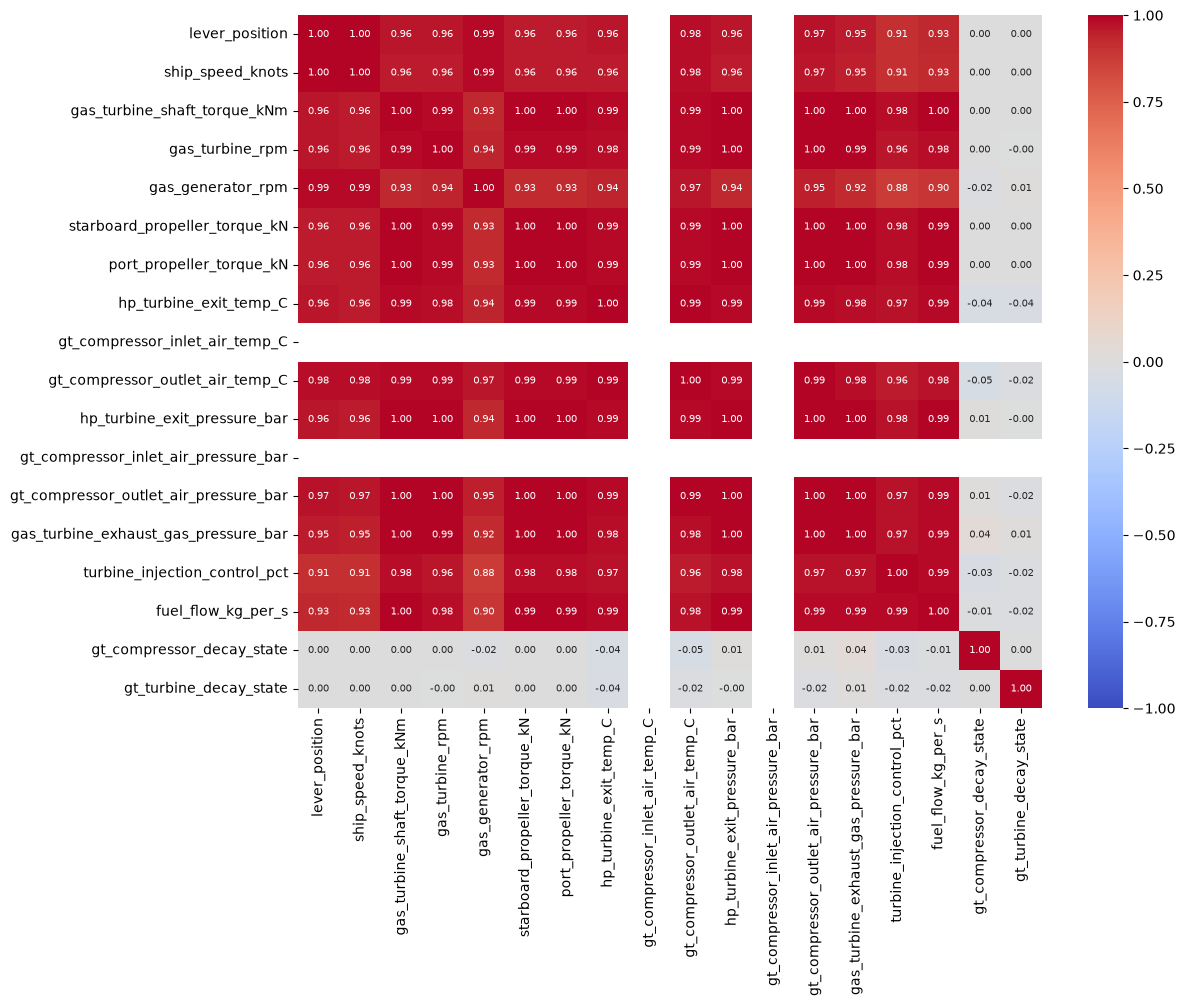

In [7]:
corr = df.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f",
            annot_kws={"size": 7}, vmin=-1, vmax=1, cmap="coolwarm")

0.9278150228106308


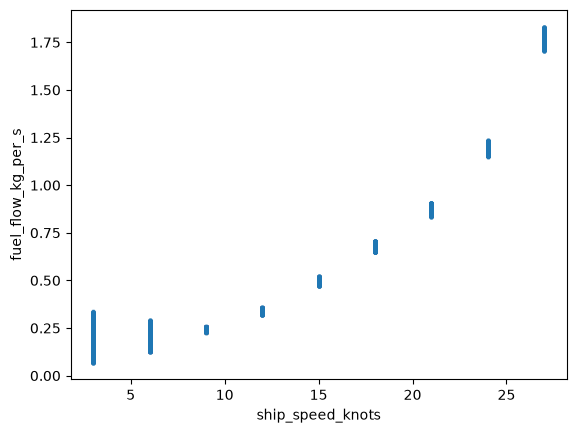

In [8]:
x, y = "ship_speed_knots", "fuel_flow_kg_per_s"
plt.scatter(df[x], df[y], s=5, alpha=0.3)
plt.xlabel(x)
plt.ylabel(y)
print(df[x].corr(df[y]))

In [11]:
sub = df[df["lever_position"] == df["lever_position"].max()]
print(len(sub))
sub.corr()[targets].drop(targets)

1326


,gt_compressor_decay_state,gt_turbine_decay_state
lever_position,NaN,NaN
ship_speed_knots,NaN,NaN
gas_turbine_shaft_torque_kNm,-0.373390,0.921058
gas_turbine_rpm,-0.557104,0.507941
gas_generator_rpm,-0.935041,0.353690
starboard_propeller_torque_kN,-0.138305,0.279258
port_propeller_torque_kN,-0.138305,0.279258
hp_turbine_exit_temp_C,-0.928653,-0.370613
gt_compressor_inlet_air_temp_C,NaN,NaN
gt_compressor_outlet_air_temp_C,-0.978387,-0.205871


gt_compressor_outlet_air_temp_C


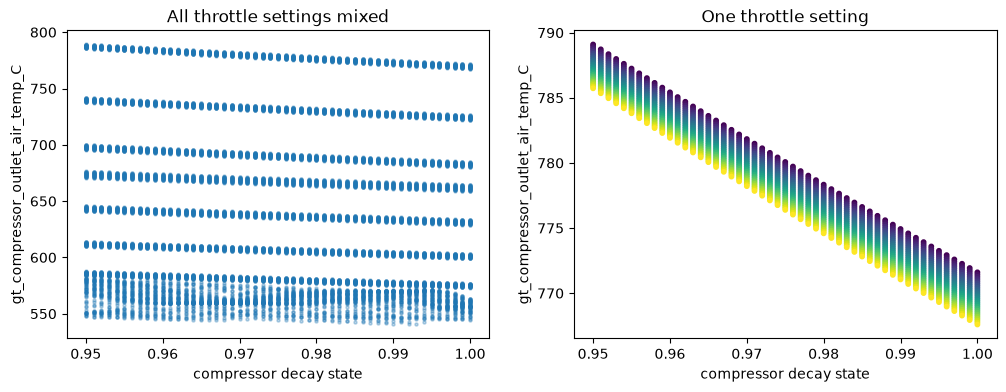

In [12]:
sensor = sub.corr()["gt_compressor_decay_state"].drop(targets).abs().idxmax()
print(sensor)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(df["gt_compressor_decay_state"], df[sensor], s=5, alpha=0.3)
axes[0].set_title("All throttle settings mixed")

axes[1].scatter(sub["gt_compressor_decay_state"], sub[sensor],
                c=sub["gt_turbine_decay_state"], s=10)
axes[1].set_title("One throttle setting")

for ax in axes:
    ax.set_xlabel("compressor decay state")
    ax.set_ylabel(sensor)